In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [35]:
KEYS=["adc_id","adc_wlpsmiles","adc_meanDAR","adc_status","adc_conjugateType","linker_smiles","linker_type","payload_smiles","payload_class","plt_acronyms",]
df=pd.read_csv("../.data/ADCdb_processed.csv").dropna(subset=KEYS)
print(df.columns)


Index(['adc_id', 'adc_name', 'adc_status', 'adc_conjugateType',
       'adc_conjugateShort', 'adc_meanDAR', 'adc_bottomDAR', 'adc_topDAR',
       'adc_wlpsmiles', 'adc_absorption', 'adc_distribution', 'adc_metabolism',
       'adc_elimination', 'adc_toxicity', 'adc_antibody_id', 'adc_linker_id',
       'adc_payload_id', 'adc_abt_id', 'adc_plt_id', 'antibody_id',
       'antibody_name', 'antibody_HC', 'antibody_vHC', 'antibody_cHC1',
       'antibody_cHC2', 'antibody_cHC3', 'antibody_LC', 'antibody_vLC',
       'antibody_cLC', 'linker_id', 'linker_name', 'linker_type',
       'linker_smiles', 'payload_id', 'payload_name', 'payload_smiles',
       'payload_class', 'abt_id', 'abt_name', 'plt_id', 'plt_name',
       'plt_acronyms', 'match_antibody', 'match_linker', 'match_payload',
       'match_abt', 'match_plt'],
      dtype='str')


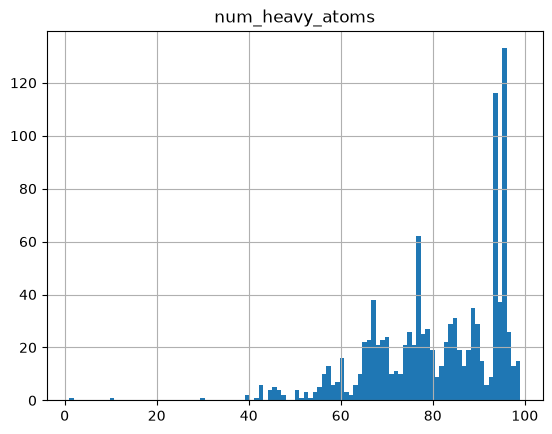

In [36]:
from rdkit.Chem import Descriptors
df["num_heavy_atoms"] = df.adc_wlpsmiles.apply(lambda x: Descriptors.HeavyAtomCount(AllChem.MolFromSmiles(x)))
df=df[df.num_heavy_atoms<100]
df.hist(column="num_heavy_atoms", bins=100)
plt.show()


In [4]:
from rdkit import Chem

# Maleimide core: five-membered imide ring with a C=C bond
MALEIMIDE_SMARTS = "[#6]1=CC(=O)N([#6,#1]*)C(=O)1"

maleimide_pattern = Chem.MolFromSmarts(MALEIMIDE_SMARTS)

def has_maleimide(smiles: str) -> bool|None:
    """
    Returns True if the molecule contains a maleimide moiety.
    """
    try:
       mol = Chem.MolFromSmiles(smiles)
    except:
        print(f"Invalid SMILES: {smiles}")
        return None
    return mol.HasSubstructMatch(maleimide_pattern)


In [5]:
from rdkit.Chem import AllChem, Draw
from wlp_chemspace.rdkit_utils import scaffold_from_smiles
murckos=set()
for smiles in df.payload_smiles.unique():
    scaffold=scaffold_from_smiles(smiles, scaffold_type="rdkit")
    if scaffold is not None and scaffold not in murckos:
        murckos.add(scaffold)
print(f"Found {len(murckos)} murcko scaffolds from {len(df)} molecules.")

Error processing SMILES 'nan': No registered converter was able to produce a C++ rvalue of type std::__1::basic_string<wchar_t, std::__1::char_traits<wchar_t>, std::__1::allocator<wchar_t>> from this Python object of type float
Found 1054 murcko scaffolds from 13090 molecules.


In [6]:
print(len(murckos))

1054
